# 01 · Exploración del dataset

Volumen de clientes, tasa de abandono, distribución de cada variable, correlación con `Exited` y variables excluidas. Toda la lógica vive en `src/` (ADR-0001).

In [1]:
import os, sys
from pathlib import Path

if "google.colab" in sys.modules:
    repo = Path("/content/deep-retention")
    if not repo.exists():
        !git clone https://github.com/Emmanuel2503/deep-retention.git {repo}
    %cd {repo}
    %pip install -q -r requirements.txt
elif Path.cwd().name == "notebooks":
    %cd ..

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

/home/gcrespo/dev/deep-retention


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from src.preprocessing import (
    CATEGORICAL,
    ID_COLUMNS,
    TARGET,
    dataset_summary,
    excluded_features,
    feature_correlations,
    input_features,
    load_dataset,
)

df = load_dataset()
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


## Volumen y tasa de abandono

In [3]:
summary = dataset_summary(df)
print(f"Clientes: {summary['n_customers']:,}")
print(f"Tasa de abandono: {summary['churn_rate']:.3f} ({summary['churn_rate']:.1%})")

Clientes: 10,000
Tasa de abandono: 0.204 (20.4%)


## Distribución de cada variable

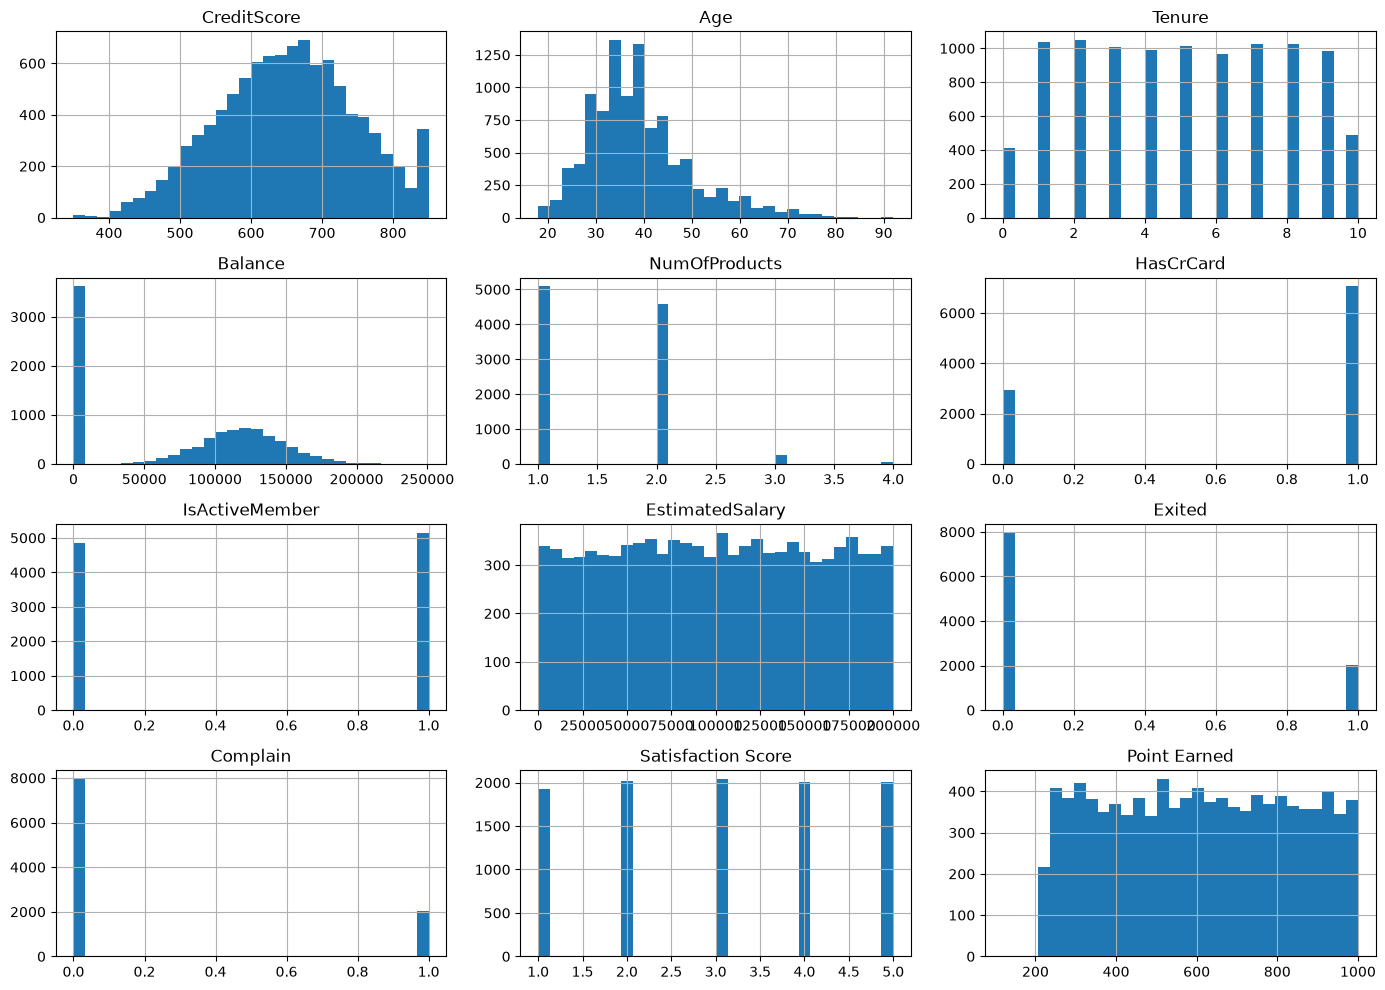

In [4]:
numeric = df.select_dtypes("number").drop(columns=ID_COLUMNS, errors="ignore")
numeric.hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

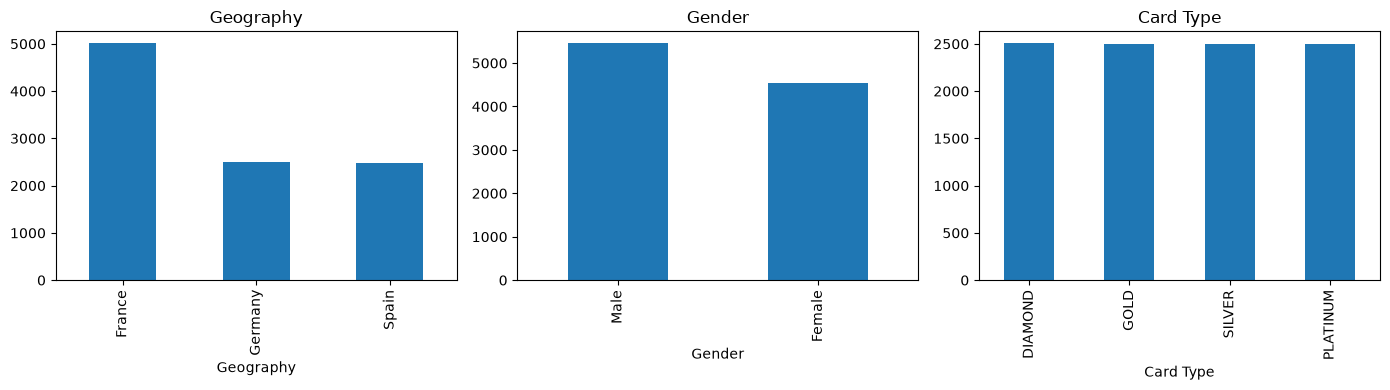

In [5]:
fig, axes = plt.subplots(1, len(CATEGORICAL), figsize=(14, 4))
for ax, col in zip(axes, CATEGORICAL):
    df[col].value_counts().plot.bar(ax=ax, title=col)
plt.tight_layout()
plt.show()

## Correlación de cada variable con `Exited`

Valor absoluto; en las categóricas, el máximo de sus columnas one-hot.

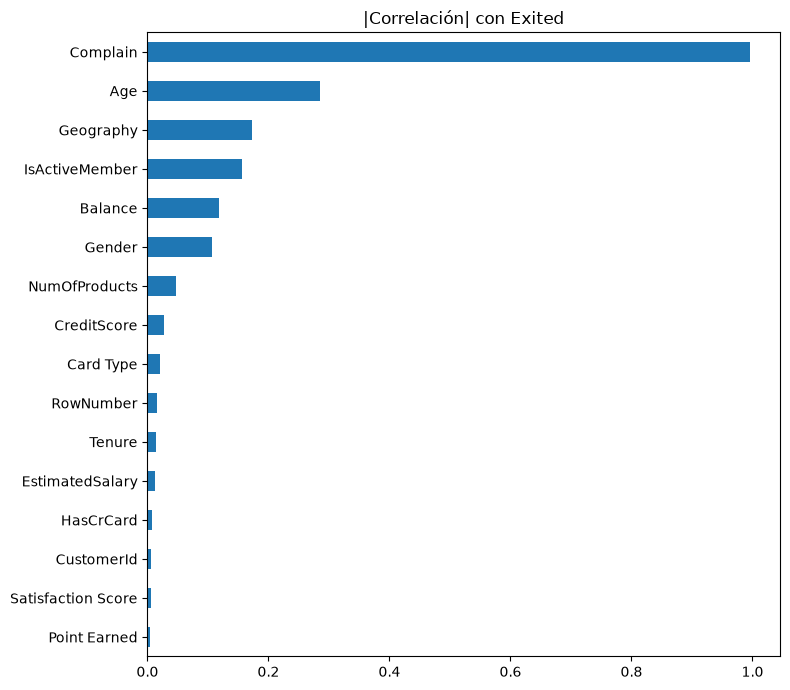

,|corr| con Exited
Complain,0.996
Age,0.285
Geography,0.173
IsActiveMember,0.156
Balance,0.119
Gender,0.106
NumOfProducts,0.048
CreditScore,0.027
Card Type,0.020
RowNumber,0.016


In [6]:
correlations = pd.Series(feature_correlations(df), name="|corr| con Exited").sort_values()
correlations.plot.barh(figsize=(8, 7), title="|Correlación| con Exited")
plt.tight_layout()
plt.show()
correlations.sort_values(ascending=False).round(3).to_frame()

## Variables excluidas y variables de entrada

In [7]:
pd.DataFrame(excluded_features(df)).rename(
    columns={"feature": "Variable", "reason": "Motivo", "correlation": "Correlación"}
).round({"Correlación": 3})

,Variable,Motivo,Correlación
0,RowNumber,identificador,NaN
1,CustomerId,identificador,NaN
2,Surname,identificador,NaN
3,Complain,fuga de datos,0.996


In [8]:
print(input_features(df))

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Satisfaction Score', 'Card Type', 'Point Earned']
